# Express Links · Week 3, step 12: train the seven graph versions (Al Zahraa)

**Goal:** all seven graph versions on the toy city (`TOY-C1`) and METR-LA, three seeds each: **42 runs**, every one with saved forecasts and a results row from the step-9 scoring code. Mean ± std over the three seeds tells us whether a gain is larger than seed-to-seed noise (proposal 3.3).

**Two stages, chosen with `MODE` in section 2**

1. **`MODE = 'pilot'`: one run first.** Trains `TOY-C1` / original graph / seed 0 for 100 epochs and, together with the step-3 METR-LA run, answers one question: *do we need 100 epochs, or is stopping at 50 just as good?* Section 7 shows the validation curves, the gain after epoch 50 and the GPU hours each choice costs. Decide, set `EPOCHS`, then switch to the second stage.
2. **`MODE = 'all'`: the 42 runs.** Works through the job list one run at a time, in seed-major order (the seven versions of seed 0 first, so the first finished block already compares the versions).

**Built for Colab disconnects.** Every epoch saves `last.pt` to Drive. Run the notebook again and it prints a **status board** (done / resumable / not started / blocked) and **continues from the last finished epoch**; nothing is lost except the epoch that was running. Each run writes a `claim.json` while it trains, so if Mohammed later opens this notebook with `WORKER = 'mohammed'` to help, the two sessions never train the same run.

**Time.** Section 5 estimates the GPU hours left from the real seconds-per-epoch of runs already in Drive (a T4 guess until the first epoch is timed), and every epoch line prints the time left in the current run. For scale: a step-3 epoch on METR-LA took about 134 s on a T4, and the toy city is about the same size, so 100 epochs is roughly **3.5 to 4 GPU-hours per run, about 160 GPU-hours for all 42**; at 50 epochs, half that. This is why the pilot comes first.

**Depends on**

| Needs | From | Status |
|---|---|---|
| `data/processed/TOY-C1/` and `data/processed/METR-LA/` | steps 2 and 8 (Mohammed) | done |
| the **seven graph files** per dataset under `data/graphs/<dataset>/` | **step 10 (Al Zahraa)** | section 4 checks which exist; missing versions show as `blocked` and are skipped, so training can start on the versions that exist |
| `code/metrics.py` | step 9 (Mohammed) | done |

**Run it:** Runtime → Change runtime type → **GPU**, check section 2, then Runtime → Run all. Keep the tab open (or use Colab Pro background execution). When it disconnects: reconnect, Run all.

## The "across a bottleneck" rule (to state in the report)

The same-side control needs a rule for which links cross a bottleneck. The proposal does not fix one, so we use the rule already built in step 5 and step 8, and we state it in the report:

> **Regions.** Each road graph is split into regions by a spectral partition of its two-way road graph: normalised Laplacian, number of regions *k* chosen by the largest eigengap for *k* = 2 … 8, k-means on the first *k* eigenvectors (step 5, fixed seed). Regions are merged into **districts** unless the boundary between them is a bottleneck, i.e. its effective-resistance jump is at least that of a reference town of two 10 × 10 grids joined by two crossings.
> **Across a bottleneck.** Two roads are *across a bottleneck* when they lie in different districts (`district` in `data/processed/<benchmark>/bottleneck/regions.npz`). For the toy cities the districts are the two grids we drew (`data/raw/toy/<city>_regions.json`), so the rule is exact.
> **Same-side control.** The 25 links with the highest lead-lag correlation ρ whose two roads are in the *same* district, matched to the express links on average ρ.

This notebook does not compute the rule (step 10 does); it only records it here so the report and the code say the same thing.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, sys, time, json
import numpy as np, pandas as pd

FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
hits = []
for root in ROOTS:
    for depth in range(4):
        hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
              "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
PROJECT_DIR = hits[0]
print('PROJECT_DIR =', PROJECT_DIR)
try:
    probe = os.path.join(PROJECT_DIR, '.write_test'); open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Mounted at /content/drive
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings

* `MODE` – `'pilot'` (one run: `TOY-C1`, original graph, seed 0, 100 epochs) or `'all'` (the 42 runs).
* `EPOCHS` / `PATIENCE` – decided after the pilot (section 7). The pilot itself always trains 100 epochs. `PATIENCE = None` trains every epoch; `PATIENCE = 10` stops a run when validation MAE has not improved for 10 epochs. **All 42 runs must use the same values**, so decide once.
* `RUNS_SUBDIR` – `'runs'` for the 100-epoch setting (where the step-3 baseline and the pilot live). If you choose another setting, give it its own folder, e.g. `'runs_e50'`, so runs with different training lengths never mix; the pilot and the baseline are then retrained at the new setting (two runs).
* `WORKER` – stays `'alzahraa'`. Only change it if a second person joins on another machine.
* `SESSION_HOURS` – stop cleanly after this many hours (useful before a known Colab cut-off); `None` = continue until no free run is left. `MAX_RUNS` and `ONLY_DATASET` narrow a session further.

Model settings are the step-3 baseline settings (Graph WaveNet defaults, learned links off) and are fixed inside `train_gwnet.py`.

In [2]:
MODE          = 'pilot'           # 'pilot' first, then 'all'
EPOCHS        = 100               # decide after the pilot: 100, or 50
PATIENCE      = None              # None, or e.g. 10 for early stopping (same for all runs)
RUNS_SUBDIR   = 'runs'            # 'runs' for 100 epochs; e.g. 'runs_e50' for another setting

WORKER        = 'alzahraa'
DATASETS      = ['TOY-C1', 'METR-LA']
SESSION_HOURS = None              # e.g. 5.5 to stop cleanly before a free-Colab cut-off
MAX_RUNS      = None
ONLY_DATASET  = None              # 'TOY-C1', 'METR-LA' or None

PILOT_JOB = dict(dataset='TOY-C1', graph='original', seed=0)

# ---------------------------------------------------------------------------------
assert MODE in ('pilot', 'all')
WORKER = WORKER.strip().lower()
ORDER = -1 if WORKER == 'mohammed' else +1           # a second worker walks the list bottom-up
if MODE == 'pilot':
    EPOCHS, PATIENCE, RUNS_SUBDIR = 100, None, 'runs'
    SETTINGS = dict(epochs=100, patience=None)
    print(f'PILOT: one run, {PILOT_JOB["dataset"]}/{PILOT_JOB["graph"]}/seed{PILOT_JOB["seed"]}, 100 epochs, in runs/')
else:
    if (EPOCHS, PATIENCE) != (100, None) and RUNS_SUBDIR == 'runs':
        raise ValueError("EPOCHS/PATIENCE differ from the 100-epoch baseline: set RUNS_SUBDIR to its own folder, e.g. 'runs_e50'")
    SETTINGS = dict(epochs=EPOCHS, patience=PATIENCE)
    print(f'ALL: 42 runs, {EPOCHS} epochs' + (f', early stop after {PATIENCE} epochs without improvement' if PATIENCE else '')
          + f', in {RUNS_SUBDIR}/; worker {WORKER}')

PILOT: one run, TOY-C1/original/seed0, 100 epochs, in runs/


## 3. The training code

`code/train_gwnet.py` is written to Drive from this cell (the same way step 9 writes `metrics.py`), so both of you run exactly the same code and the GitHub repo gets it from there. It is the step-3 training loop turned into a function, plus the claim / resume / scoring logic. Read the docstring at the top of the file for the run-folder layout.

Then Graph WaveNet is fetched at the pinned commit with the same `Conv1d → Conv2d` patch as step 3.

In [3]:
CODE_DIR = os.path.join(PROJECT_DIR, "code"); os.makedirs(CODE_DIR, exist_ok=True)
MODULE_SRC = r'''"""
Express Links · step 12 · train_gwnet.py  (owners: both)

One module that runs the 42 (later 84) Graph WaveNet runs so that two people can train
in parallel from the same Drive folder, stop at any time, and continue where they left off.

How a run works
  runs/<dataset>/<graph>/seed<k>/
     claim.json            who is training this run right now (worker, host, last heartbeat)
     last.pt               every epoch: model + optimizer + history + RNG state  -> resume point
     best.pt               the epoch with the lowest validation MAE
     log.csv               one row per epoch (train/val errors, seconds)
     test_predictions.npz  forecasts of best.pt on the test set: pred (S, 12, N) mph, t_anchor, horizon_min
     test_by_horizon.csv   MAE / RMSE / MAPE for each of the 12 horizons
     results.json          settings + test errors + timing, 'step12': True marks the run as finished
     score.json            written by metrics.score_run (step 9) right after the run finishes

Picking the next run (two workers, no coordinator)
  A worker walks the job list (worker A top-down, worker B bottom-up, so they meet in the middle),
  skips finished runs, skips runs another worker has claimed and heart-beaten in the last
  CLAIM_STALE_MIN minutes, and takes the first free one. Claims are files on Drive, so a crashed
  session's claim goes stale on its own and the other worker (or the same one, after a restart)
  picks the run up from last.pt.

Model and training settings are the step-3 baseline settings (Graph WaveNet defaults, learned
links OFF). They are the same for every graph version, so the only thing that differs between
the seven runs of a seed is the graph file.
"""
import os, sys, json, time, glob, random, socket, platform, subprocess, inspect, pickle
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------------------------
# Settings shared by every run (step 3 values). Do not change between runs.
# ----------------------------------------------------------------------------------------------
DEFAULTS = dict(epochs=100, patience=None, batch_size=64, lr=1e-3, weight_decay=1e-4, dropout=0.3, nhid=32,
                adj_type='doubletransition', adaptive_adj=False)
# patience=None: always train all `epochs`. patience=N: stop when validation MAE has not improved for N epochs.
GWN_REPO   = 'https://github.com/nnzhan/Graph-WaveNet.git'
GWN_COMMIT = '6b162e80c59a1d494809252eca055cff93dc66b1'

GRAPH_VERSIONS = ['original', 'random', 'map_only', 'corr_only', 'same_side', 'express', 'virtual_node']
SEEDS = [0, 1, 2]
ORIGINAL_GRAPHS = {'METR-LA': 'adj_mx.pkl', 'PEMS-BAY': 'adj_mx_bay.pkl'}   # under data/raw/

CLAIM_STALE_MIN = 30      # a claim with no heartbeat for this long is treated as abandoned
# rough seconds per epoch (train + validation) on a Colab T4, used only until a real epoch is timed
GUESS_SEC_PER_EPOCH = {'METR-LA': 145, 'PEMS-BAY': 230, 'TOY': 135}


# ----------------------------------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------------------------------
def find_project_dir():
    """The shared Coding folder on a mounted Drive, or EXPRESS_PROJECT_DIR for local tests."""
    env = os.environ.get('EXPRESS_PROJECT_DIR')
    if env:
        return env
    folder = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
    roots = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
    hits = []
    for root in roots:
        for depth in range(4):
            hits += glob.glob(os.path.join(root, *(['*'] * depth), folder))
    hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
    assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
                  "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun.")
    return hits[0]


def data_dir(project_dir, dataset):
    return os.path.join(project_dir, 'data', 'processed', dataset)


def original_graph(project_dir, dataset):
    if dataset in ORIGINAL_GRAPHS:
        return os.path.join(project_dir, 'data', 'raw', ORIGINAL_GRAPHS[dataset])
    return os.path.join(project_dir, 'data', 'raw', 'toy', f'{dataset}_adj_mx.pkl')   # TOY-C*, Sharjah


def graph_file(project_dir, dataset, version, k=25):
    """Where step 10 (Al Zahraa) puts the graph versions. 'original' is the raw road graph.
    Accepts a few spellings so a small naming difference does not block training."""
    if version == 'original':
        return original_graph(project_dir, dataset)
    gdir = os.path.join(project_dir, 'data', 'graphs', dataset)
    candidates = [f'{version}_K{k}.pkl', f'{version}.pkl', f'{dataset}_{version}_K{k}.pkl', f'{dataset}_{version}.pkl',
                  f'{version}-K{k}.pkl', f'{version.replace("_", "-")}_K{k}.pkl', f'{version.replace("_", "")}_K{k}.pkl']
    for c in candidates:
        p = os.path.join(gdir, c)
        if os.path.exists(p):
            return p
    return os.path.join(gdir, candidates[0])     # the expected name, even if missing (checked later)


def run_dir(project_dir, dataset, version, seed, runs_subdir='runs'):
    return os.path.join(project_dir, runs_subdir, dataset, version, f'seed{seed}')


# ----------------------------------------------------------------------------------------------
# Job list and status
# ----------------------------------------------------------------------------------------------
def job_list(datasets, versions=GRAPH_VERSIONS, seeds=SEEDS):
    """Seed-major order: all seven versions of seed 0 first, so the first finished block already
    compares the versions; then seed 1, then seed 2."""
    return [dict(dataset=d, graph=v, seed=s) for s in seeds for d in datasets for v in versions]


def read_json(path, default=None):
    try:
        with open(path) as f:
            return json.load(f)
    except (OSError, ValueError):
        return default


def job_status(project_dir, job, runs_subdir='runs', epochs=DEFAULTS['epochs']):
    """One of: done, test_pending (training finished, forecasts not yet written), in_progress
    (someone holds a live claim), resumable (checkpoint, no live claim), not_started, blocked
    (graph file missing), conflict (checkpoint made with other settings)."""
    rd = run_dir(project_dir, job['dataset'], job['graph'], job['seed'], runs_subdir)
    gf = graph_file(project_dir, job['dataset'], job['graph'])
    st = dict(job, run_dir=rd, graph_file=gf, epoch=0, best_val_mae=np.nan, worker='', sec_per_epoch=np.nan)
    res = read_json(os.path.join(rd, 'results.json'), {})
    log = os.path.join(rd, 'log.csv')
    if os.path.exists(log):
        try:
            h = pd.read_csv(log)
            st['epoch'] = int(h['epoch'].max())
            st['best_val_mae'] = float(h['val_mae'].min())
            col = 'epoch_sec' if 'epoch_sec' in h else 'train_sec'
            st['sec_per_epoch'] = float(h[col].tail(10).median())
        except Exception:
            pass
    claim = read_json(os.path.join(rd, 'claim.json'), {})
    live = claim and (time.time() - claim.get('heartbeat', 0)) < CLAIM_STALE_MIN * 60
    if live:
        st['worker'] = claim.get('worker', '?')
    if res.get('step12') and os.path.exists(os.path.join(rd, 'test_predictions.npz')):
        st['status'] = 'done'
    elif not os.path.exists(gf):
        st['status'] = 'blocked'
    elif live and not res.get('step12'):
        st['status'] = 'in_progress'
    elif os.path.exists(os.path.join(rd, 'last.pt')):
        finished = st['epoch'] >= epochs or os.path.exists(os.path.join(rd, 'train_done.json'))
        if finished and os.path.exists(os.path.join(rd, 'best.pt')):
            st['status'] = 'test_pending'
        else:
            st['status'] = 'resumable'
    else:
        st['status'] = 'not_started'
    st['scored'] = os.path.exists(os.path.join(rd, 'score.json'))
    return st


def status_board(project_dir, jobs, runs_subdir='runs', epochs=DEFAULTS['epochs']):
    rows = [job_status(project_dir, j, runs_subdir, epochs) for j in jobs]
    return pd.DataFrame(rows)


def sec_per_epoch_estimate(board, dataset, epochs=DEFAULTS['epochs']):
    """Median measured epoch time for this dataset from any run's log; otherwise a T4 guess."""
    m = board[(board['dataset'] == dataset) & board['sec_per_epoch'].notna()]
    if len(m):
        return float(m['sec_per_epoch'].median()), 'measured'
    key = dataset if dataset in GUESS_SEC_PER_EPOCH else 'TOY'
    return float(GUESS_SEC_PER_EPOCH[key]), 'guess (T4)'


def time_estimate(board, epochs=DEFAULTS['epochs'], workers=2, test_min=4.0):
    """Remaining GPU time for the runs on the board, and per worker if split evenly."""
    rows, total = [], 0.0
    for ds, g in board.groupby('dataset', sort=False):
        spe, how = sec_per_epoch_estimate(board, ds, epochs)
        left_epochs = sum(max(0, epochs - int(r.epoch)) for r in g.itertuples() if r.status != 'done')
        left_tests = int(((g['status'] != 'done')).sum())
        hours = (left_epochs * spe + left_tests * test_min * 60) / 3600
        total += hours
        rows.append(dict(dataset=ds, runs_left=left_tests, epochs_left=left_epochs,
                         sec_per_epoch=round(spe), source=how, gpu_hours_left=round(hours, 1)))
    out = pd.DataFrame(rows)
    return out, total, total / max(workers, 1)


# ----------------------------------------------------------------------------------------------
# Claims (so two Colab sessions never train the same run)
# ----------------------------------------------------------------------------------------------
def _claim_path(rd):
    return os.path.join(rd, 'claim.json')


def write_claim(rd, worker):
    os.makedirs(rd, exist_ok=True)
    tmp = _claim_path(rd) + '.tmp'
    with open(tmp, 'w') as f:
        json.dump(dict(worker=worker, host=socket.gethostname(), heartbeat=time.time(),
                       time=time.strftime('%Y-%m-%d %H:%M:%S')), f)
    os.replace(tmp, _claim_path(rd))


def release_claim(rd):
    try:
        os.remove(_claim_path(rd))
    except OSError:
        pass


def try_claim(rd, worker, settle_sec=20):
    """Claim a run. Waits settle_sec and re-reads the file, so that two workers starting the
    same run within a few seconds of each other (Drive sync delay) both notice."""
    c = read_json(_claim_path(rd), {})
    if c and c.get('worker') != worker and (time.time() - c.get('heartbeat', 0)) < CLAIM_STALE_MIN * 60:
        return False
    write_claim(rd, worker)
    time.sleep(settle_sec)
    c = read_json(_claim_path(rd), {})
    return bool(c) and c.get('worker') == worker


def next_job(project_dir, jobs, worker, order, runs_subdir='runs', epochs=DEFAULTS['epochs'], only_dataset=None,
             skip=()):
    """First free job in this worker's walking order (order = +1 top-down, -1 bottom-up)."""
    seq = jobs if order > 0 else list(reversed(jobs))
    for job in seq:
        if only_dataset and job['dataset'] != only_dataset:
            continue
        if (job['dataset'], job['graph'], job['seed']) in skip:
            continue
        st = job_status(project_dir, job, runs_subdir, epochs)
        if st['status'] in ('done', 'blocked', 'in_progress'):
            continue
        if try_claim(st['run_dir'], worker):
            return job, st
    return None, None


# ----------------------------------------------------------------------------------------------
# Graph WaveNet code (official repo, pinned commit, Conv1d -> Conv2d patch as in step 3)
# ----------------------------------------------------------------------------------------------
def setup_graph_wavenet(gwn_dir='/content/Graph-WaveNet'):
    if not os.path.isdir(gwn_dir):
        subprocess.run(['git', 'clone', '-q', GWN_REPO, gwn_dir], check=True)
    subprocess.run(['git', '-C', gwn_dir, 'checkout', '-q', GWN_COMMIT], check=True)
    model_py = os.path.join(gwn_dir, 'model.py')
    src = open(model_py).read()
    if 'nn.Conv1d(' in src:
        open(model_py, 'w').write(src.replace('nn.Conv1d(', 'nn.Conv2d('))
        if 'model' in sys.modules or 'engine' in sys.modules:
            raise RuntimeError('The unpatched model is already loaded. Runtime -> Restart session, then Run all.')
    if gwn_dir not in sys.path:
        sys.path.insert(0, gwn_dir)
    import util, engine   # noqa: F401  (import check)
    return gwn_dir


def set_seed(seed):
    import torch
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def save_atomic(obj, path):
    import torch
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load_graph_for_data(gfile, orig_file, N):
    """Loads a graph version and checks it against the data.
    Returns (sensor_ids, adj_mx as a dense array, n_virtual): n_virtual = 1 when the graph has one
    extra node with no readings (the global virtual node version); its data column is padded with
    zeros, which Graph WaveNet's masked loss and metrics ignore."""
    import util
    sensor_ids, _, adj = util.load_pickle(gfile)
    orig_ids = util.load_pickle(orig_file)[0]
    adj = np.asarray(adj, dtype=np.float32)
    ids = [str(s) for s in sensor_ids]
    oids = [str(s) for s in orig_ids]
    assert len(ids) in (N, N + 1), f'graph has {len(ids)} sensors, data has {N}: {gfile}'
    assert ids[:N] == oids[:N], f'sensor order differs from the original graph: {gfile}'
    n_virtual = len(ids) - N
    assert adj.shape == (len(ids), len(ids)), f'adjacency is {adj.shape}, expected ({len(ids)}, {len(ids)})'
    return sensor_ids, adj, n_virtual


def pad_virtual(data, n_virtual):
    """Adds n_virtual all-zero sensor columns to x and y (speed 0 = masked; time-of-day copied)."""
    if n_virtual == 0:
        return data
    import util
    for cat in ['train', 'val', 'test']:
        for key in ['x_' + cat, 'y_' + cat]:
            a = data[key]
            pad = np.zeros(a.shape[:2] + (n_virtual, a.shape[3]), dtype=a.dtype)
            pad[..., 1:] = a[:, :, :1, 1:]            # same time-of-day feature as sensor 0
            data[key] = np.concatenate([a, pad], axis=2)
        bs = data[cat + '_loader'].batch_size
        data[cat + '_loader'] = util.DataLoader(data['x_' + cat], data['y_' + cat], bs)
    return data


# ----------------------------------------------------------------------------------------------
# One run: resume -> train -> test -> results -> score
# ----------------------------------------------------------------------------------------------
def train_run(project_dir, job, worker, settings=None, runs_subdir='runs', gwn_dir='/content/Graph-WaveNet',
              log=print, stop_after=None, score=True):
    """Trains (or resumes) one run and writes everything listed at the top of this file.
    stop_after: optional time.time() deadline; the loop stops cleanly after the epoch that
    crosses it (the run stays resumable). Returns the status string of the run afterwards."""
    import torch
    import util
    from engine import trainer

    cfg = dict(DEFAULTS, **(settings or {}))
    ds, version, seed = job['dataset'], job['graph'], job['seed']
    rd = run_dir(project_dir, ds, version, seed, runs_subdir)
    dd = data_dir(project_dir, ds)
    gf = graph_file(project_dir, ds, version)
    of = original_graph(project_dir, ds)
    os.makedirs(rd, exist_ok=True)
    for p in [os.path.join(dd, f'{s}.npz') for s in ['train', 'val', 'test']] + [gf, of]:
        assert os.path.exists(p), f'Missing {p}'

    write_claim(rd, worker)
    t_run0 = time.time()
    try:
        set_seed(seed)
        device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
        if device.type == 'cpu':
            log('WARNING: no GPU. Runtime -> Change runtime type -> GPU.')

        data = util.load_dataset(dd, cfg['batch_size'], cfg['batch_size'], cfg['batch_size'])
        scaler = data['scaler']
        t_anchor_test = np.load(os.path.join(dd, 'test.npz'))['t_anchor']
        N = data['x_train'].shape[2]
        sensor_ids, adj_mx, n_virtual = load_graph_for_data(gf, of, N)
        data = pad_virtual(data, n_virtual)
        n_nodes = N + n_virtual
        supports = [torch.tensor(a, dtype=torch.float32).to(device)
                    for a in [util.asym_adj(adj_mx), util.asym_adj(np.transpose(adj_mx))]]
        assert cfg['adj_type'] == 'doubletransition'
        n_links = int((adj_mx > 0).sum())

        engine = trainer(scaler, in_dim=2, seq_length=12, num_nodes=n_nodes, nhid=cfg['nhid'],
                         dropout=cfg['dropout'], lrate=cfg['lr'], wdecay=cfg['weight_decay'], device=device,
                         supports=supports, gcn_bool=True, addaptadj=cfg['adaptive_adj'], aptinit=None)
        assert not any('nodevec' in n for n, _ in engine.model.named_parameters()), 'learned links are ON'
        n_params = sum(p.numel() for p in engine.model.parameters())

        config = dict(dataset=ds, graph=version, graph_file=os.path.basename(gf), seed=seed,
                      epochs=cfg['epochs'], patience=cfg['patience'], batch_size=cfg['batch_size'], lr=cfg['lr'],
                      weight_decay=cfg['weight_decay'], dropout=cfg['dropout'], nhid=cfg['nhid'],
                      adj_type=cfg['adj_type'], adaptive_adj=cfg['adaptive_adj'], gwn_commit=GWN_COMMIT)

        # ---- resume ----
        LAST, BEST = os.path.join(rd, 'last.pt'), os.path.join(rd, 'best.pt')
        start_epoch, history, train_seconds = 1, [], 0.0
        if os.path.exists(LAST):
            ck = torch.load(LAST, map_location='cpu', weights_only=False)
            old = dict(ck['config'])
            ignore = ('epochs', 'patience')
            same = {k: v for k, v in old.items() if k not in ignore} == {k: v for k, v in config.items() if k not in ignore}
            if not same:
                log(f'CONFLICT: {rd} was made with other settings:\n  {old}\n  skipping it. Delete the folder to retrain.')
                return 'conflict'
            engine.model.load_state_dict(ck['model'])
            engine.optimizer.load_state_dict(ck['optimizer'])
            seen, history = set(), []
            for h in ck['history']:                       # drop duplicate epoch rows, if any
                if h['epoch'] not in seen:
                    seen.add(h['epoch']); history.append(h)
            train_seconds = ck['train_seconds']
            start_epoch = ck['epoch'] + 1
            torch.set_rng_state(ck['torch_rng'])
            if ck.get('cuda_rng') is not None and torch.cuda.is_available():
                try:
                    torch.cuda.set_rng_state_all(ck['cuda_rng'])
                except Exception:
                    pass
            if start_epoch <= cfg['epochs']:
                log(f'Resuming {ds}/{version}/seed{seed} after epoch {ck["epoch"]} '
                    f'(best val MAE so far {min(h["val_mae"] for h in history):.4f})')
        else:
            log(f'Starting {ds}/{version}/seed{seed}: {n_nodes} nodes ({n_virtual} virtual), '
                f'{n_links:,} non-zero graph entries, {n_params:,} parameters')

        # ---- train ----
        train_loader = data['train_loader']
        X, Y, n_batches, bs = train_loader.xs, train_loader.ys, train_loader.num_batch, cfg['batch_size']
        if os.path.exists(os.path.join(rd, 'train_done.json')):
            start_epoch = cfg['epochs'] + 1              # training finished earlier (early stop); only the test is left
        for epoch in range(start_epoch, cfg['epochs'] + 1):
            t_e0 = time.time()
            perm = np.random.default_rng(seed * 10_000 + epoch).permutation(train_loader.size)
            tr = []
            for b in range(n_batches):
                idx = perm[b * bs:(b + 1) * bs]
                x = torch.from_numpy(X[idx]).float().to(device).transpose(1, 3)
                y = torch.from_numpy(Y[idx]).float().to(device).transpose(1, 3)
                tr.append(engine.train(x, y[:, 0, :, :]))
            t_train = time.time() - t_e0
            va = []
            with torch.no_grad():
                for x, y in data['val_loader'].get_iterator():
                    x = torch.from_numpy(x).float().to(device).transpose(1, 3)
                    y = torch.from_numpy(y).float().to(device).transpose(1, 3)
                    va.append(engine.eval(x, y[:, 0, :, :]))
            tr, va = np.mean(tr, axis=0), np.mean(va, axis=0)
            train_seconds += t_train
            row = dict(epoch=epoch, train_mae=tr[0], train_mape=tr[1] * 100, train_rmse=tr[2],
                       val_mae=va[0], val_mape=va[1] * 100, val_rmse=va[2], train_sec=t_train,
                       epoch_sec=time.time() - t_e0)
            is_best = not history or row['val_mae'] < min(h['val_mae'] for h in history)
            history.append(row)
            if is_best:
                save_atomic({'model': engine.model.state_dict(), 'epoch': epoch, 'val_mae': row['val_mae'],
                             'config': config}, BEST)
            save_atomic({'model': engine.model.state_dict(), 'optimizer': engine.optimizer.state_dict(),
                         'epoch': epoch, 'history': history, 'train_seconds': train_seconds, 'config': config,
                         'torch_rng': torch.get_rng_state(),
                         'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, LAST)
            pd.DataFrame(history).to_csv(os.path.join(rd, 'log.csv'), index=False)
            write_claim(rd, worker)                                   # heartbeat
            spe = float(np.median([h['epoch_sec'] for h in history[-10:]]))
            eta_h = (cfg['epochs'] - epoch) * spe / 3600
            log(f'{ds}/{version}/seed{seed} epoch {epoch:3d}/{cfg["epochs"]} | train MAE {row["train_mae"]:.3f} '
                f'| val MAE {row["val_mae"]:.3f} RMSE {row["val_rmse"]:.3f} MAPE {row["val_mape"]:.2f}% '
                f'| {row["epoch_sec"]:.0f} s | ~{eta_h:.1f} h left in this run' + ('  <- best' if is_best else ''))
            best_epoch = min(history, key=lambda h: h['val_mae'])['epoch']
            if cfg['patience'] and epoch - best_epoch >= cfg['patience']:
                with open(os.path.join(rd, 'train_done.json'), 'w') as f:
                    json.dump(dict(stopped_early=True, epoch=epoch, best_epoch=best_epoch, patience=cfg['patience']), f)
                log(f'Early stop: no improvement for {cfg["patience"]} epochs (best epoch {best_epoch}).')
                break
            if stop_after is not None and time.time() > stop_after:
                log('Session time budget reached: stopping cleanly. Run the notebook again to continue.')
                release_claim(rd)
                return 'resumable'

        if not os.path.exists(os.path.join(rd, 'train_done.json')):
            with open(os.path.join(rd, 'train_done.json'), 'w') as f:
                json.dump(dict(stopped_early=False, epoch=len(history)), f)

        # ---- test the best epoch (input padded with one step, as the official test.py does) ----
        best = torch.load(BEST, map_location='cpu', weights_only=False)
        engine.model.load_state_dict(best['model'])
        engine.model.eval()
        outs = []
        with torch.no_grad():
            for x, _ in data['test_loader'].get_iterator():
                x = torch.from_numpy(x).float().to(device).transpose(1, 3)
                x = torch.nn.functional.pad(x, (1, 0, 0, 0))
                outs.append(engine.model(x).transpose(1, 3)[:, 0, :, :])
        S = data['y_test'].shape[0]
        yhat = scaler.inverse_transform(torch.cat(outs, dim=0)[:S])[:, :N, :]            # drop virtual node
        real = torch.from_numpy(data['y_test'][..., 0]).float().to(device).transpose(1, 2)[:, :N, :]
        per_h = []
        for h in range(12):
            mae, mape, rmse = util.metric(yhat[:, :, h], real[:, :, h])
            per_h.append(dict(horizon=h + 1, minutes=5 * (h + 1), mae=mae, rmse=rmse, mape=mape * 100))
        per_h = pd.DataFrame(per_h)
        avg = per_h[['mae', 'rmse', 'mape']].mean()
        pred_np = yhat.transpose(1, 2).cpu().numpy().astype(np.float32)
        np.savez_compressed(os.path.join(rd, 'test_predictions.npz'), pred=pred_np,
                            t_anchor=t_anchor_test, horizon_min=np.arange(5, 61, 5))
        per_h.to_csv(os.path.join(rd, 'test_by_horizon.csv'), index=False)

        results = dict(config,
                       best_epoch=int(best['epoch']), best_val_mae=float(best['val_mae']),
                       **{f'{m}_{k}min': float(per_h.set_index('minutes').loc[k, m])
                          for k in [15, 30, 60] for m in ['mae', 'rmse', 'mape']},
                       mae_avg=float(avg['mae']), rmse_avg=float(avg['rmse']), mape_avg=float(avg['mape']),
                       params=int(n_params), n_virtual=int(n_virtual), graph_nonzero=n_links,
                       epochs_run=len(history), stopped_early=bool(read_json(os.path.join(rd, 'train_done.json'), {}).get('stopped_early')),
                       train_hours=round(train_seconds / 3600, 3),
                       sec_per_epoch=round(float(np.mean([h.get('epoch_sec', h['train_sec']) for h in history])), 1),
                       gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
                       torch=torch.__version__, python=platform.python_version(),
                       worker=worker, finished=time.strftime('%Y-%m-%d %H:%M'), step12=True)
        with open(os.path.join(rd, 'results.json'), 'w') as f:
            json.dump(results, f, indent=2)
        append_results_row(os.path.join(project_dir, runs_subdir, 'results.csv'), results)
        log(f'DONE {ds}/{version}/seed{seed}: best epoch {best["epoch"]}, test MAE 15/30/60 min = '
            f'{results["mae_15min"]:.3f} / {results["mae_30min"]:.3f} / {results["mae_60min"]:.3f} mph '
            f'({(time.time() - t_run0) / 60:.0f} min this session)')

        if score:
            score_run(project_dir, rd, dd, log)
        return 'done'
    finally:
        release_claim(rd)


def append_results_row(table_path, results):
    table = pd.read_csv(table_path) if os.path.exists(table_path) else pd.DataFrame()
    if len(table):
        table = table[~((table['dataset'] == results['dataset']) & (table['graph'] == results['graph'])
                        & (table['seed'] == results['seed']))]
    table = pd.concat([table, pd.DataFrame([results])], ignore_index=True)
    table.to_csv(table_path, index=False)


def score_run(project_dir, rd, dd, log=print):
    """Calls step 9's metrics.score_run on a finished run (writes run_dir/score.json)."""
    code_dir = os.path.join(project_dir, 'code')
    if code_dir not in sys.path:
        sys.path.insert(0, code_dir)
    try:
        import metrics as M
        params = inspect.signature(M.score_run).parameters
        kw = {}
        if 'raw_toy' in params:
            kw['raw_toy'] = os.path.join(project_dir, 'data', 'raw', 'toy')
        row = M.score_run(rd, dd, **kw)
        keys = [k for k in ('jam_recall_30', 'jam_recall_60', 'jam_precision_60', 'jam_recall_60_behind') if k in row]
        log('scored: ' + ', '.join(f'{k} {row[k]:.3f}' for k in keys if isinstance(row[k], float)))
        return row
    except Exception as e:                      # scoring must never lose a finished run
        log(f'(scoring skipped: {type(e).__name__}: {e}. Rerun the step-9 notebook later; the run is saved.)')
        return None


# ----------------------------------------------------------------------------------------------
# The worker loop
# ----------------------------------------------------------------------------------------------
def work(project_dir, jobs, worker, order=1, settings=None, runs_subdir='runs', max_runs=None,
         session_hours=None, only_dataset=None, log=print, score=True):
    """Keeps taking free jobs until none are left, max_runs is reached or the session budget ends."""
    cfg = dict(DEFAULTS, **(settings or {}))
    deadline = time.time() + session_hours * 3600 if session_hours else None
    done, skip = 0, set()
    while True:
        if deadline and time.time() > deadline:
            log('Session time budget used up. Run the notebook again later to continue.')
            break
        if max_runs is not None and done >= max_runs:
            break
        job, st = next_job(project_dir, jobs, worker, order, runs_subdir, cfg['epochs'], only_dataset, skip)
        if job is None:
            board = status_board(project_dir, jobs, runs_subdir, cfg['epochs'])
            left = board[board['status'] != 'done']
            if len(left) == 0:
                log('All runs are done.')
            else:
                log(f'No free run to take right now: {len(left)} not done, of which '
                    f'{(left["status"] == "in_progress").sum()} in progress elsewhere and '
                    f'{(left["status"] == "blocked").sum()} waiting for a graph file.')
            break
        log(f'\n=== {worker} takes {job["dataset"]}/{job["graph"]}/seed{job["seed"]} ({st["status"]}) ===')
        result = train_run(project_dir, job, worker, settings, runs_subdir, log=log, stop_after=deadline, score=score)
        if result == 'done':
            done += 1
        elif result == 'resumable':
            break
        elif result == 'conflict':
            skip.add((job['dataset'], job['graph'], job['seed']))
    return done
'''

with open(os.path.join(CODE_DIR, 'train_gwnet.py'), 'w') as f:
    f.write(MODULE_SRC)
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
import importlib, train_gwnet as T
T = importlib.reload(T)
print('Saved', os.path.join(CODE_DIR, 'train_gwnet.py'))

Saved /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/code/train_gwnet.py


In [4]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || echo "No GPU found: Runtime -> Change runtime type -> GPU"
T.setup_graph_wavenet('/content/Graph-WaveNet')
import torch
print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'No GPU: Runtime -> Change runtime type -> GPU, then Run all.'

Tesla T4, 15360 MiB
torch 2.11.0+cu130 | CUDA available: True


## 4. Check the inputs and the job list

The job list is seed-major: the seven versions of seed 0 first (so the first finished block already compares all versions), then seed 1, then seed 2.

Graph versions are expected at `data/graphs/<dataset>/<version>_K25.pkl` with `<version>` in `random, map_only, corr_only, same_side, express, virtual_node` (`original` is the raw road graph). The sensor order must match the original graph; the `virtual_node` file may have one extra node at the end, which the code pads with an always-masked data column. **Missing files are Al Zahraa's step 10**; they show as `blocked` below and are skipped, not failed, so run what exists and rerun the notebook when the rest arrive.

In [5]:
JOBS = [PILOT_JOB] if MODE == 'pilot' else T.job_list(DATASETS)
print(f'{len(JOBS)} job(s)' + ('' if MODE == 'pilot' else f': {len(DATASETS)} datasets x {len(T.GRAPH_VERSIONS)} versions x {len(T.SEEDS)} seeds'))

rows = []
for ds in DATASETS:
    dd = T.data_dir(PROJECT_DIR, ds)
    ok = all(os.path.exists(os.path.join(dd, f'{s}.npz')) for s in ['train', 'val', 'test'])
    rows.append(dict(dataset=ds, what='data (steps 2 / 8)', file=os.path.relpath(dd, PROJECT_DIR), exists=ok))
    for v in T.GRAPH_VERSIONS:
        gf = T.graph_file(PROJECT_DIR, ds, v)
        rows.append(dict(dataset=ds, what=f'graph: {v}', file=os.path.relpath(gf, PROJECT_DIR), exists=os.path.exists(gf)))
rows.append(dict(dataset='-', what='scoring (step 9)', file='code/metrics.py',
                 exists=os.path.exists(os.path.join(CODE_DIR, 'metrics.py'))))
inputs = pd.DataFrame(rows)
display(inputs)
missing = inputs[~inputs['exists']]
if len(missing):
    print(f'{len(missing)} input(s) missing. Graph versions come from step 10 (Al Zahraa); '
          'the runs that need them are skipped until the files appear.')
else:
    print('OK  every input is in place')

1 job(s)


,dataset,what,file,exists
0,TOY-C1,data (steps 2 / 8),data/processed/TOY-C1,False
1,TOY-C1,graph: original,data/raw/toy/TOY-C1_adj_mx.pkl,False
2,TOY-C1,graph: random,data/graphs/TOY-C1/random_K25.pkl,False
3,TOY-C1,graph: map_only,data/graphs/TOY-C1/map_only_K25.pkl,False
4,TOY-C1,graph: corr_only,data/graphs/TOY-C1/corr_only_K25.pkl,False
5,TOY-C1,graph: same_side,data/graphs/TOY-C1/same_side_K25.pkl,False
6,TOY-C1,graph: express,data/graphs/TOY-C1/express_K25.pkl,False
7,TOY-C1,graph: virtual_node,data/graphs/TOY-C1/virtual_node_K25.pkl,False
8,METR-LA,data (steps 2 / 8),data/processed/METR-LA,True
9,METR-LA,graph: original,data/raw/adj_mx.pkl,True


15 input(s) missing. Graph versions come from step 10 (Al Zahraa); the runs that need them are skipped until the files appear.


## 5. Status board and time estimate

Statuses: **done** (forecasts + results written), **test_pending** (all epochs trained, only the test pass left: minutes), **in_progress** (another session holds a live claim), **resumable** (a checkpoint and no live claim: the next worker continues it), **not_started**, **blocked** (graph file missing).

The estimate uses the median seconds per epoch (train + validation) of any run of the same dataset in Drive; before the first epoch is timed it uses a T4 guess and says so.

In `pilot` mode the board has one row and the estimate is for that run only.

In [6]:
board = T.status_board(PROJECT_DIR, JOBS, RUNS_SUBDIR, EPOCHS)
show = board[['dataset', 'graph', 'seed', 'status', 'epoch', 'best_val_mae', 'worker', 'scored']]
display(show.style.apply(lambda s: ['background-color: #d9f2e3' if v == 'done' else
                                    'background-color: #fde9d0' if v == 'in_progress' else
                                    'background-color: #e8e8e8' if v == 'blocked' else '' for v in s], subset=['status']))
print(board['status'].value_counts().to_string())

est, total_h, each_h = T.time_estimate(board, EPOCHS, workers=2)
display(est)
print(f'GPU time left: about {total_h:.0f} h ({each_h:.0f} h each if a second person also runs this notebook)'
      + ('' if (est['source'] == 'measured').all() else '  (T4 guess until the first epoch is timed)'))
if SESSION_HOURS:
    spe = max(T.sec_per_epoch_estimate(board, ds, EPOCHS)[0] for ds in DATASETS)
    print(f'This session ({SESSION_HOURS} h) covers about {SESSION_HOURS * 3600 / spe:.0f} epochs, '
          f'{SESSION_HOURS * 3600 / spe / EPOCHS:.1f} runs.')

,dataset,graph,seed,status,epoch,best_val_mae,worker,scored
0,TOY-C1,original,0,blocked,0,nan,,False


status
blocked    1


,dataset,runs_left,epochs_left,sec_per_epoch,source,gpu_hours_left
0,TOY-C1,1,100,135,guess (T4),3.8


GPU time left: about 4 h (2 h each if a second person also runs this notebook)  (T4 guess until the first epoch is timed)


## 6. Train

Takes the first run that is not done (in `pilot` mode, the pilot run), trains or resumes it, tests the best epoch, writes the results row, scores it, releases the claim, and takes the next one. Stops when there is no free run left (or at `SESSION_HOURS` / `MAX_RUNS`).

Each epoch line ends with the time left in that run. If the notebook is interrupted, run it again: it continues after the last finished epoch.

In [7]:
n_done = T.work(PROJECT_DIR, JOBS, WORKER, order=ORDER, settings=SETTINGS, runs_subdir=RUNS_SUBDIR,
                max_runs=MAX_RUNS, session_hours=SESSION_HOURS, only_dataset=ONLY_DATASET)
print(f'\n{WORKER} finished {n_done} run(s) in this session')
if MODE == 'pilot' and n_done:
    print('Pilot done. Look at section 7, then set MODE = "all" and EPOCHS / PATIENCE / RUNS_SUBDIR in section 2.')

No free run to take right now: 1 not done, of which 0 in progress elsewhere and 1 waiting for a graph file.

alzahraa finished 0 run(s) in this session


## 7. Pilot: 100 epochs, or stop at 50?

Uses every 100-epoch run in `runs/` (the step-3 METR-LA baseline and the pilot). A 50-epoch run with the same seed sees exactly the same batches as the first 50 epochs of a 100-epoch run (the shuffle of epoch *e* depends only on seed and *e*), so "best validation MAE within the first 50 epochs" **is** what a 50-epoch run would have scored on validation.

How to read the table: `gain_after_50` is how much validation MAE still improved between epoch 50 and 100. Seed-to-seed noise for Graph WaveNet is a few hundredths of a mph, so a gain under about **0.03 mph** is not worth doubling the GPU time; a gain above it means 100 epochs matter. The `patience` column shows at which epoch a patience-10 early stop would have ended the run, and what it would have cost in validation MAE.

,best_epoch,val_mae_100,val_mae_50,gain_after_50,patience10_stops_at,val_mae_patience10,sec_per_epoch,hours_per_run_100,hours_per_run_50,hours_21_runs_100,hours_21_runs_50
dataset,,,,,,,,,,,
METR-LA,82,2.769,2.8,0.031,55,2.8,143,4.0,2.0,84,42


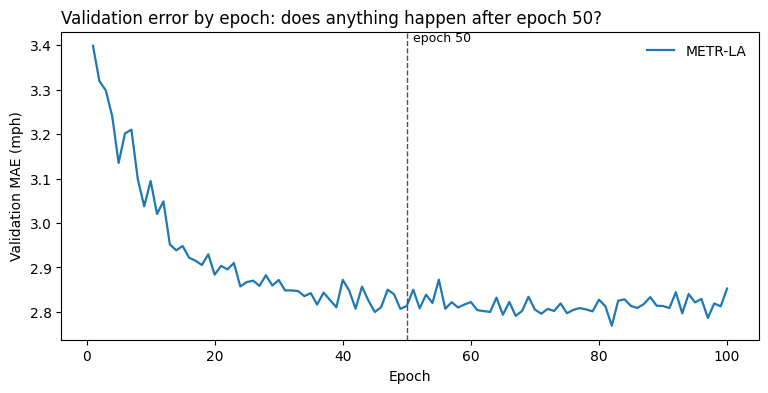

All 42 runs: about 84 GPU-hours at 100 epochs, 42 at 50 epochs.
Largest gain after epoch 50: 0.031 mph (noise yardstick 0.03) -> suggested: KEEP 100 EPOCHS
  100 epochs  -> section 2: EPOCHS = 100, PATIENCE = None, RUNS_SUBDIR = "runs"  (baseline and pilot already count)
  50 epochs   -> section 2: EPOCHS = 50,  PATIENCE = None, RUNS_SUBDIR = "runs_e50"  (baseline and pilot are retrained at 50: 2 extra runs)
Write the choice and this table in the report (training settings).


In [8]:
import matplotlib.pyplot as plt
NOISE = 0.03          # mph; the seed-to-seed noise level used as the yardstick
CUT, PAT = 50, 10

rows, curves = [], {}
for p in sorted(glob.glob(os.path.join(PROJECT_DIR, 'runs', '*', 'original', 'seed0', 'log.csv'))):
    h = pd.read_csv(p).drop_duplicates('epoch').sort_values('epoch')
    if h['epoch'].max() < 100:
        continue
    ds = p.split(os.sep)[-4]
    curves[ds] = h
    best100, best50 = h['val_mae'].min(), h[h['epoch'] <= CUT]['val_mae'].min()
    best_ep = int(h.loc[h['val_mae'].idxmin(), 'epoch'])
    running = h['val_mae'].cummin()
    stop_ep = next((int(e) for e, r in zip(h['epoch'], running) if e - int(h.loc[running[running == r].index[0], 'epoch']) >= PAT), 100)
    best_pat = h[h['epoch'] <= stop_ep]['val_mae'].min()
    spe = float(h['epoch_sec'].median()) if 'epoch_sec' in h else float(h['train_sec'].median()) + 10
    rows.append(dict(dataset=ds, best_epoch=best_ep, val_mae_100=round(best100, 3), val_mae_50=round(best50, 3),
                     gain_after_50=round(best50 - best100, 3), patience10_stops_at=stop_ep,
                     val_mae_patience10=round(best_pat, 3), sec_per_epoch=round(spe),
                     hours_per_run_100=round(100 * spe / 3600, 1), hours_per_run_50=round(CUT * spe / 3600, 1),
                     hours_21_runs_100=round(21 * 100 * spe / 3600), hours_21_runs_50=round(21 * CUT * spe / 3600)))
if not rows:
    print('No finished 100-epoch run yet. Run the pilot (MODE = "pilot") first.')
else:
    pilot = pd.DataFrame(rows).set_index('dataset')
    display(pilot)
    fig, ax = plt.subplots(figsize=(9, 4))
    for ds, h in curves.items():
        ax.plot(h['epoch'], h['val_mae'], lw=1.6, label=ds)
    ax.axvline(CUT, color='#52514e', ls='--', lw=1); ax.text(CUT + 1, ax.get_ylim()[1], 'epoch 50', va='top', fontsize=9)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Validation MAE (mph)'); ax.legend(frameon=False)
    ax.set_title('Validation error by epoch: does anything happen after epoch 50?', loc='left')
    plt.show()
    total100, total50 = pilot['hours_21_runs_100'].sum(), pilot['hours_21_runs_50'].sum()
    verdict = 'KEEP 100 EPOCHS' if (pilot['gain_after_50'] > NOISE).any() else 'STOP AT 50 EPOCHS'
    print(f'All 42 runs: about {total100:.0f} GPU-hours at 100 epochs, {total50:.0f} at 50 epochs.')
    print(f'Largest gain after epoch 50: {pilot["gain_after_50"].max():.3f} mph (noise yardstick {NOISE}) -> suggested: {verdict}')
    print('  100 epochs  -> section 2: EPOCHS = 100, PATIENCE = None, RUNS_SUBDIR = "runs"  (baseline and pilot already count)')
    print('  50 epochs   -> section 2: EPOCHS = 50,  PATIENCE = None, RUNS_SUBDIR = "runs_e50"  (baseline and pilot are retrained at 50: 2 extra runs)')
    print('Write the choice and this table in the report (training settings).')

## 8. Where we are now, and the scores so far

In [9]:
board = T.status_board(PROJECT_DIR, JOBS, RUNS_SUBDIR, EPOCHS)
display(board[['dataset', 'graph', 'seed', 'status', 'epoch', 'best_val_mae', 'worker', 'scored']])
print(board['status'].value_counts().to_string())
est, total_h, each_h = T.time_estimate(board, EPOCHS, workers=2)
print(f'GPU time left: about {total_h:.0f} h')

,dataset,graph,seed,status,epoch,best_val_mae,worker,scored
0,TOY-C1,original,0,blocked,0,NaN,,False


status
blocked    1
GPU time left: about 4 h


In [10]:
# Rebuild runs/scores.csv and the mean +- std table from every scored run (step-9 code)
import metrics as M, inspect
run_dirs = sorted(os.path.dirname(p) for p in glob.glob(os.path.join(PROJECT_DIR, RUNS_SUBDIR, '*', '*', 'seed*', 'test_predictions.npz'))
                  if '/check-' not in p.replace(os.sep, '/'))
print(f'{len(run_dirs)} run folder(s) with forecasts')
if run_dirs and hasattr(M, 'score_many'):
    args = [run_dirs, os.path.join(PROJECT_DIR, 'data', 'processed')]
    if len(inspect.signature(M.score_many).parameters) >= 3:
        args.append(os.path.join(PROJECT_DIR, 'data', 'raw', 'toy'))
    table = M.score_many(*args, table_path=os.path.join(PROJECT_DIR, RUNS_SUBDIR, 'scores.csv'))
    cols = [c for c in ['dataset', 'graph', 'seed', 'mae_15', 'mae_30', 'mae_60', 'jam_recall_30', 'jam_recall_60',
                        'jam_precision_60', 'jam_recall_60_behind', 'mae_60_behind'] if c in table.columns]
    display(table[cols].round(3))
    if hasattr(M, 'summarise'):
        summary = M.summarise(table)
        summary.to_csv(os.path.join(PROJECT_DIR, RUNS_SUBDIR, 'scores_summary.csv'))
        display(summary)
elif run_dirs:
    display(pd.read_csv(os.path.join(PROJECT_DIR, RUNS_SUBDIR, 'results.csv'))
            [['dataset', 'graph', 'seed', 'mae_15min', 'mae_30min', 'mae_60min', 'best_epoch', 'train_hours', 'worker']].round(3))

ModuleNotFoundError: No module named 'metrics'

## Done

Step 12 is done when the board in section 8 shows **42 × done** and every row is **scored**. Then:

* **Step 16 (Mohammed):** `runs/scores.csv` → the main results table (mean ± std over seeds) and the jam-recall-at-60-min figure.
* **Step 17 (Mohammed):** paired bootstrap, express vs same-side.
* **Report:** copy the "across a bottleneck" rule from the top of this notebook; list the GPU (`gpu` in `results.json`), epochs, `train_hours` per run and library versions, as the setup section requires.

**If something goes wrong**

* *A run shows `in_progress` but nobody is training it:* the claim goes stale 30 minutes after the last heartbeat; rerun section 6 after that, or delete that folder's `claim.json`.
* *`CONFLICT ... made with other settings`:* a folder holds a checkpoint from different settings (e.g. an earlier test). Delete the folder to retrain, or keep it and leave that run to whoever made it.
* *`blocked`:* the graph file for that version is missing; ask Al Zahraa (step 10) and rerun.
* *Scoring skipped:* the run is saved anyway; rerun the step-9 notebook's "score every run" cell later.